# 09 · Train full-dataset distillation through epochs 14–16

Continue the unmasked epoch-13 U-Net using true middle drawings and AnimeInbet predictions. Use all 58,390 training and 29,188 validation examples with GMA motion. The current `EXTRA_EPOCHS=3` trains epochs 14–16.

**Setup:** Kaggle with a GPU, Stage 1 data, and the epoch-13 checkpoint. Enable Internet for initial model/data downloads, or attach the required files. Attach prior caches and results to resume.

**Saves:** A model and training state for each completed epoch, validation reports, animations, and separate results/cache ZIPs.

In [ ]:
from pathlib import Path

BASE = Path("/kaggle/input/datasets/epicfaez")
DATA = BASE / "interframes-stage1-output/interframes_tf_stage1"
EPOCH13_DIR = BASE / "interframes-stage2-ink15/interframes_tf_stage2_ink15"
OUT = Path("/kaggle/working/interframes_kd09")
CACHE = Path("/kaggle/working/interframes_kd09_cache")
TEMP = Path("/kaggle/temp/interframes_kd09")
# Optional: old 08 cache root or 09 cache folder/ZIP, and prior 09 results folder/ZIP.
# Use multiple cache roots when one is a partial backup. Only missing files are imported.
CACHE_INPUTS = []
RESULTS_INPUT = None
RAW_ZIP = None  # Original ml240data.zip. Otherwise downloaded directly on Kaggle.
TEACHER_CKPT = None  # Authors' epoch_20.pt, if attached.
GMA_CKPT = None
EXTRA_EPOCHS = 3  # Increase to 2 or 3 and rerun training/report cells.
BATCH_SIZE, SEED, GMA_ITERS = 4, 42, 12
LEARNING_RATE, KD_MAX_WEIGHT = 2e-5, 0.20
SAVE_EVERY_BATCHES = 1000
VAL_BLOCK = 256
assert EXTRA_EPOCHS in (1, 2, 3) and BATCH_SIZE > 0 and SAVE_EVERY_BATCHES > 0
for directory in (OUT, CACHE, TEMP):
    directory.mkdir(parents=True, exist_ok=True)

## Verify the full dataset and parent model

Check the inputs, dataset identifier, complete example lists, and epoch-13 checkpoint before preparing motion or teacher predictions.

In [ ]:
import collections, contextlib, csv, gc, hashlib, importlib.util, json, math
import os, random, re, shutil, subprocess, sys, time, zipfile
from functools import lru_cache

import numpy as np
from PIL import Image
from scipy.ndimage import distance_transform_edt
from tqdm.auto import tqdm
from IPython.display import display, FileLink

# Kaggle normally supplies SciPy, PIL, NumPy, PyTorch, OpenCV, and TensorFlow.
assert (DATA / "stage1_complete.json").is_file(), f"Attach Stage 1: {DATA}"
assert (DATA / "modules/data.py").is_file(), "Stage 1 modules/data.py missing"
assert (EPOCH13_DIR / "training_state.json").is_file(), (
    f"Attach unmasked ink15: {EPOCH13_DIR}"
)
sys.path.insert(0, str(DATA / "modules"))
import data as raster


def read_json(p):
    return json.loads(Path(p).read_text())


def atomic_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".part")
    tmp.write_text(json.dumps(obj, indent=2, sort_keys=True, default=str))
    tmp.replace(path)


def sha256(path, block=4 << 20):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()


stage = read_json(DATA / "stage1_complete.json")
state13 = read_json(EPOCH13_DIR / "training_state.json")
base_cfg = state13["run_config"]
assert state13.get("experiment") == "epoch10_ink30_to_ink15", (
    "Not the unmasked ink-15 experiment"
)
assert base_cfg.get("positive_weight") == 15, "Requires the unmasked ink-15 model"
assert base_cfg.get("data_fingerprint") == stage["fingerprint"], (
    "Stage 1 fingerprint differs"
)
assert base_cfg.get("feature_version") == "tf-ink8-lowflow16-v2", (
    "Unexpected feature version"
)
assert not state13.get("partial") or state13.get("best_epoch") == 13, (
    "Partial model with no verified epoch-13 best"
)
if state13["completed_epochs"] == 13 and not state13.get("partial"):
    BASE_PATH = EPOCH13_DIR / "last.keras"
elif state13.get("best_epoch") == 13:
    BASE_PATH = EPOCH13_DIR / "best.keras"
else:
    raise ValueError(
        "Attach an unmasked checkpoint with actual epoch-13 weights, not just epoch-13 history."
    )
assert BASE_PATH.is_file(), BASE_PATH
base_entry = next(h for h in state13["history"] if h["epoch"] == 13)
BASE_DIGEST = base_entry["weights_digest"]
SIZE = int(read_json(DATA / "config.json")["size"])
assert SIZE == 256 and len(BASE_DIGEST) == 64, "Check Stage 1 size and epoch-13 digest"

all_rows = raster.read_records(DATA)
tr_rows = [r for r in all_rows if r["split"] == "train"]
va_rows = [r for r in all_rows if r["split"] == "val"]
assert tr_rows and va_rows, "Training / validation manifest missing"
assert {r["sequence"] for r in tr_rows}.isdisjoint({r["sequence"] for r in va_rows})


train_rows, val_rows = tr_rows, va_rows
rows = train_rows + val_rows
row_by_id = {r["id"]: r for r in rows}
assert (len(train_rows), len(val_rows)) == (58390, 29188)
assert len(row_by_id) == len(rows) and all(len(r["id"]) == 20 for r in rows)
assert (
    len(train_rows) == stage["triplets"]["train"]
    and len(val_rows) == stage["triplets"]["val"]
)
GMA_REV = "2f1fd29468a86a354d44dd25d107930b3f175043"
GMA_SHA_PREFIX = (
    "4a9faacbec5d"  # Logged by the verified pilot; store the full digest on first use.
)
ANIME_REV = "cc5554feb9d8943f1fc5f0b90854ef15cd3e8335"
FLOW_DIR = CACHE / "gma_coarse_flow"
TEACHER_DIR = CACHE / "teacher"


def teacher_png_path(r):
    return TEACHER_DIR / "predictions" / r["split"] / (r["id"] + ".png")


def flow_path(r):
    return FLOW_DIR / r["split"] / (r["id"] + ".npy")


flow_sig = dict(
    stage_fingerprint=stage["fingerprint"],
    mode="coarse",
    size=SIZE,
    iterations=GMA_ITERS,
    repo_revision=GMA_REV,
)
teacher_sig = dict(
    stage_fingerprint=stage["fingerprint"],
    repo_revision=ANIME_REV,
    line_width=2,
    preparation="original_ml240_graphs_to_256px_v1",
)
print(
    f"{len(train_rows):,} training | {len(val_rows):,} validation | parent: {BASE_PATH}"
)

58,390 training | 29,188 validation | parent: /kaggle/input/datasets/epicfaez/interframes-stage2-ink15/interframes_tf_stage2_ink15/last.keras


## Restore caches and results

Set `CACHE_INPUTS` to compatible cache folders or ZIPs and `RESULTS_INPUT` to previous training results. Merge checked partial caches. The pilot’s results-only ZIP has no motion files or teacher PNGs.

In [ ]:
import pandas as pd
from contextlib import ExitStack


def source_root(src, marker):
    src = Path(src)
    if src.is_dir():
        matches = (
            [src]
            if (src / marker).is_file()
            else [
                p.parents[len(Path(marker).parts) - 1] for p in src.glob("*/" + marker)
            ]
        )
        if len(matches) != 1:
            raise ValueError(f"Select the folder containing {marker}: {src}")
        return matches[0]
    if not src.is_file():
        raise FileNotFoundError(src)
    # Extract requested files directly to their final destination in import_cache/import_results.
    return src


def copy_member(src, dest):
    dest.parent.mkdir(parents=True, exist_ok=True)
    tmp = dest.with_name("." + dest.name + ".part")
    with tmp.open("wb") as f:
        shutil.copyfileobj(src, f, 2**20)
    tmp.replace(dest)


@contextlib.contextmanager
def reader(src, marker):
    src = source_root(src, marker)
    if src.is_dir():
        yield src, lambda rel: (src / rel).open("rb"), None
    else:
        with zipfile.ZipFile(src) as z:
            roots = [
                n[: -len(marker)]
                for n in z.namelist()
                if n == marker or n.endswith("/" + marker)
            ]
            if len(roots) != 1:
                raise ValueError(f"Expected one {marker} in {src}")
            prefix = roots[0]
            names = {
                n[len(prefix) :]
                for n in z.namelist()
                if n.startswith(prefix) and not n.endswith("/")
            }
            yield None, lambda rel: z.open(prefix + str(rel)), names


def check_fields(actual, expected):
    for key, value in expected.items():
        if actual.get(key) != value:
            raise ValueError(f"Cache mismatch at {key}: {actual.get(key)} vs {value}")


def use_marker(path, expected):
    if path.is_file():
        check_fields(read_json(path), expected)
    else:
        atomic_json(path, expected)


def record_flow(actual):
    check_fields(actual, flow_sig)
    digest = actual.get("checkpoint_sha256", "")
    if len(digest) != 64 or not digest.startswith(GMA_SHA_PREFIX):
        raise ValueError("GMA checkpoint differs from pilot.")
    use_marker(FLOW_DIR / "provenance.json", dict(flow_sig, checkpoint_sha256=digest))


def copy_cache_inputs():
    inputs = list(CACHE_INPUTS)
    for name in ("interframes_distillation08", "interframes_distillation08_inkfix"):
        path = OUT.parent / name
        if (path / "gma_coarse_flow/provenance.json").is_file() and path not in inputs:
            inputs.append(path)
    teacher_meta = (
        read_json(TEACHER_DIR / "provenance.json")
        if (TEACHER_DIR / "provenance.json").exists()
        else None
    )
    if teacher_meta:
        check_fields(teacher_meta, teacher_sig)
        assert teacher_meta.get("checkpoint_sha256", "").startswith("fe7896878df4"), (
            "Teacher differs from pilot"
        )
    if (FLOW_DIR / "provenance.json").exists():
        record_flow(read_json(FLOW_DIR / "provenance.json"))
    for src in inputs:
        with reader(src, "gma_coarse_flow/provenance.json") as (root, op, names):
            with op("gma_coarse_flow/provenance.json") as f:
                record_flow(json.load(f))
            tm = "teacher/provenance.json"
            have_teacher = tm in names if names is not None else (root / tm).is_file()
            if have_teacher:
                with op(tm) as f:
                    incoming = json.load(f)
                check_fields(incoming, teacher_sig)
                assert incoming["checkpoint_sha256"].startswith("fe7896878df4"), (
                    "Different teacher than pilot"
                )
                use_marker(
                    TEACHER_DIR / "provenance.json",
                    dict(teacher_sig, checkpoint_sha256=incoming["checkpoint_sha256"]),
                )
            for r in tqdm(rows, desc=f"Import partial cache {Path(src).name}"):
                paths = [flow_path(r)] + ([teacher_png_path(r)] if have_teacher else [])
                for dest in paths:
                    if dest.exists():
                        continue
                    rel = dest.relative_to(CACHE).as_posix()
                    if rel in names if names is not None else (root / rel).is_file():
                        with op(rel) as f:
                            copy_member(f, dest)


def restore_results():
    if not RESULTS_INPUT:
        return
    if any(p.name != "experiment_config.json" for p in OUT.iterdir()):
        print(
            "Using existing working results. An attached results snapshot is restored into a fresh output folder."
        )
        return
    with reader(RESULTS_INPUT, "experiment_config.json") as (root, op, names):
        with op("experiment_config.json") as f:
            saved = json.load(f)
        check_fields(saved, config)
        paths = (
            names
            if names is not None
            else (
                f.relative_to(root).as_posix() for f in root.rglob("*") if f.is_file()
            )
        )
        # Stage and rename as one unit. An interrupted restore cannot expose half a checkpoint.
        import tempfile

        with tempfile.TemporaryDirectory(
            dir=OUT.parent, prefix=".kd09-restore-"
        ) as staging:
            stage_dir = Path(staging) / "results"
            stage_dir.mkdir()
            for rel in paths:
                p = Path(rel)
                if (
                    p.is_absolute()
                    or ".." in p.parts
                    or any(k.startswith(".") for k in p.parts)
                ):
                    continue
                with op(rel) as f:
                    copy_member(f, stage_dir / p)
            if (OUT / "experiment_config.json").exists():
                (OUT / "experiment_config.json").unlink()
            OUT.rmdir()
            stage_dir.rename(OUT)


config = dict(
    parent=BASE_DIGEST,
    stage=stage["fingerprint"],
    flow=flow_sig,
    teacher_revision=ANIME_REV,
    batch=BATCH_SIZE,
    seed=SEED,
    lr=LEARNING_RATE,
    kd=KD_MAX_WEIGHT,
    loss="08_inkfix_v2_weight8",
    train=len(train_rows),
    val=len(val_rows),
    val_block=VAL_BLOCK,
    ids=hashlib.sha256("\n".join(r["id"] for r in rows).encode()).hexdigest(),
)
use_marker(OUT / "experiment_config.json", config)
restore_results()
copy_cache_inputs()

Import partial cache interframes_distillation08:   0%|          | 0/87578 [00:00<?, ?it/s]

## Cache GMA motion

Estimate movement in both directions and save a compact motion file per example. Schedule only missing or invalid files. The same worker can estimate motion between generated drawings for later animations.

In [ ]:
%%writefile /kaggle/working/gma_worker09.py
import argparse, json, sys
from pathlib import Path
import numpy as np
import torch
from PIL import Image
from tqdm.auto import tqdm

repo, checkpoint, root, out, jobs_path, steps = sys.argv[1:]
sys.path.insert(0, str(Path(repo) / "core"))
from network import RAFTGMA

args = argparse.Namespace(
    small=False,
    mixed_precision=False,
    alternate_corr=False,
    dropout=0.0,
    num_heads=1,
    position_only=False,
    position_and_content=False,
)
device = "cuda" if torch.cuda.is_available() else "cpu"
model = RAFTGMA(args)
weights = torch.load(checkpoint, map_location="cpu", weights_only=True)
model.load_state_dict(
    {k.removeprefix("module."): v for k, v in weights.items()}, strict=True
)
model.to(device).eval()


def frame(p):
    with Image.open(Path(root) / p) as im:
        arr = np.asarray(im.convert("RGB"))
    return torch.from_numpy(arr.copy()).permute(2, 0, 1).float()


jobs = json.loads(Path(jobs_path).read_text())
with torch.inference_mode():
    for r in tqdm(jobs, desc="Cache GMA coarse flows"):
        dest = Path(out) / r["split"] / (r["id"] + ".npy")
        dest.parent.mkdir(parents=True, exist_ok=True)
        if dest.exists():
            existing = np.load(dest, mmap_mode="r")
            if (
                existing.shape == (2, 32, 32, 2)
                and existing.dtype == np.float16
                and np.isfinite(existing).all()
            ):
                continue
            raise RuntimeError(f"Corrupt cached flow: {dest}")
        pair = torch.stack([frame(r["a"]), frame(r["b"])]).to(device)
        h, w = pair.shape[-2:]
        assert h == w == 256, (h, w)
        low, _ = model(pair, pair.flip(0), iters=int(steps), test_mode=True)
        assert tuple(low.shape) == (2, 2, 32, 32) and torch.isfinite(low).all()
        result = low.permute(0, 2, 3, 1).cpu().numpy().astype(np.float16)
        tmp = dest.with_suffix(".part.npy")
        np.save(tmp, result)
        tmp.replace(dest)

Overwriting /kaggle/working/gma_worker09.py


In [ ]:
WORKER = Path("/kaggle/working/gma_worker09.py")


def pinned_repo(name, url, rev):
    repo = TEMP / name
    if not (repo / ".git").exists():
        subprocess.run(["git", "clone", "--quiet", url, str(repo)], check=True)
    subprocess.run(["git", "-C", str(repo), "checkout", "--quiet", rev], check=True)
    return repo


def need_package(module, package):
    if importlib.util.find_spec(module) is None:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", package], check=True
        )


@lru_cache(maxsize=1)
def gma_assets():
    repo = pinned_repo("GMA", "https://github.com/zacjiang/GMA.git", GMA_REV)
    if GMA_CKPT:
        ckpt = Path(GMA_CKPT)
    else:
        from huggingface_hub import hf_hub_download

        ckpt = Path(
            hf_hub_download(
                "dreMaz/AnimeRun_ckpt",
                "20000_gma-animerun-v2-ft.pth",
                revision="76eeaa2ebfcd8714088faabcd65bacc7d621cd15",
            )
        )
    record_flow(dict(flow_sig, checkpoint_sha256=sha256(ckpt)))
    return repo, ckpt


def run_gma(jobs, root, dest):
    if not jobs:
        return
    repo, ckpt = gma_assets()
    jobs_path = TEMP / "gma_jobs.json"
    atomic_json(jobs_path, jobs)
    subprocess.run(
        [
            sys.executable,
            str(WORKER),
            str(repo),
            str(ckpt),
            str(root),
            str(dest),
            str(jobs_path),
            str(GMA_ITERS),
        ],
        check=True,
    )


def ensure_flows():
    missing = []
    for r in tqdm(rows, desc="Check GMA cache"):
        dest = flow_path(r)
        if dest.is_file():
            try:
                f = np.load(dest, allow_pickle=False)
                if (
                    f.shape == (2, SIZE // 8, SIZE // 8, 2)
                    and f.dtype == np.float16
                    and np.isfinite(f).all()
                ):
                    continue
            except (ValueError, OSError, EOFError):
                pass
            dest.unlink()
        missing.append({k: r[k] for k in ("id", "split", "a", "b")})
    print(
        f"GMA: {len(rows) - len(missing):,} cached, {len(missing):,} to compute.",
        flush=True,
    )
    run_gma(missing, DATA, FLOW_DIR)
    record_flow(read_json(FLOW_DIR / "provenance.json"))


ensure_flows()

Check GMA cache:   0%|          | 0/87578 [00:00<?, ?it/s]

GMA: 87,578 cached, 0 to compute.


## Cache AnimeInbet middle drawings

Open the original ML240 archive and prepare endpoint graphs. Run the fixed teacher only for missing predictions. Render its lines at the original image size with a two-pixel pen, then apply Stage 1 resizing. Teacher generation uses only endpoint inputs.

In [ ]:
def teacher_inputs(png, label):
    # Use native coordinates until after rendering, as in notebook 07.
    rgb = cv2.imdecode(np.frombuffer(png, np.uint8), cv2.IMREAD_COLOR)
    graph = json.loads(label)
    xy = np.asarray(graph["vertex location"], dtype=np.int64)
    xy = np.clip(xy, [0, 0], [rgb.shape[1] - 1, rgb.shape[0] - 1])
    neighbors = [list(nbs) + [i] for i, nbs in enumerate(graph["connection"])]
    adj = from_adjacency_list(neighbors, matrix_only=True, reindex=False)
    np.random.seed(int.from_bytes(hashlib.sha256(label).digest()[:4], "little"))
    spec = np.abs(Spectral(64, normalized=False).fit_transform(adj))
    if spec.shape[0] != len(xy) or spec.shape[1] > 64:
        raise ValueError(f"Unsupported graph embedding shape {spec.shape}")
    spec = np.pad(spec, ((0, 0), (0, 64 - spec.shape[1])))
    image = torch.from_numpy(rgb).permute(2, 0, 1).float() * (2 / 255.0) - 1
    return xy, neighbors, image, spec


def render_teacher(net, endpoints):
    batch = {"gen_vid": True}
    for j, (xy, topo, img, spec) in enumerate(endpoints):
        for name, v in (
            ("image", img),
            ("keypoints", xy),
            ("spec", spec),
            ("mask", np.ones(len(xy), np.float32)),
        ):
            batch[f"{name}{j}"] = torch.as_tensor(v).unsqueeze(0).to(device)
        batch[("ms", "ns")[j]] = torch.tensor([len(xy)], device=device)
    with torch.inference_mode():
        res = net(batch)
    canvas = np.full(endpoints[0][2].shape[-2:], 255, np.uint8)
    for j, (xy, topo, _, _) in enumerate(endpoints):
        motion = res[f"r{j}"][0].float().cpu().numpy()
        logits = res[f"vb{j}"][0].float().cpu().numpy()
        if not np.isfinite(motion).all() or not np.isfinite(logits).all():
            raise ValueError("Non-finite teacher output")
        # Apply the upstream generation edge-stretch check on CPU. Its updates
        # are sequential; GPU synchronization per edge is expensive on Kaggle.
        xy = xy.astype(np.float32)
        moved = xy + motion
        for u, nbs in enumerate(topo):
            lengths = np.sum((xy[u] - xy[nbs]) ** 2, axis=1)
            stretched = np.sum((moved[u] - moved[nbs]) ** 2, axis=1) > 3 * (
                lengths + 1e-7
            )
            for v in np.asarray(nbs)[stretched]:
                if logits[u] != 0 and logits[v] != 0:
                    logits[u] = logits[v] = 0
        middle = (xy + 0.5 * motion).astype(np.int32)
        keep = logits > 0
        for u, nbs in enumerate(topo):
            for v in nbs:
                if u != v and keep[u] and keep[v]:
                    cv2.line(canvas, tuple(middle[u]), tuple(middle[v]), 0, thickness=2)
    return raster.prepare_image(Image.fromarray(canvas), size=SIZE)


def ensure_teachers():
    missing = []
    for r in tqdm(rows, desc="Check AnimeInbet cache"):
        dest = teacher_png_path(r)
        if dest.is_file():
            try:
                with Image.open(dest) as im:
                    if im.size == (SIZE, SIZE) and im.mode == "L":
                        im.verify()
                        continue
            except (OSError, ValueError, SyntaxError):
                pass
        missing.append(r)
    print(
        f"AnimeInbet: {len(rows) - len(missing):,} cached, {len(missing):,} to compute.",
        flush=True,
    )
    if not missing:
        check_fields(read_json(TEACHER_DIR / "provenance.json"), teacher_sig)
        return
    for m, pkg in (
        ("sknetwork", "scikit-network"),
        ("easydict", "easydict"),
        ("gdown", "gdown"),
    ):
        need_package(m, pkg)
    global torch, cv2, from_adjacency_list, Spectral, device
    import torch, cv2, yaml, gdown
    from sknetwork.data import from_adjacency_list
    from sknetwork.embedding import Spectral
    from easydict import EasyDict
    from huggingface_hub import hf_hub_download

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    repo = pinned_repo(
        "AnimeInbet", "https://github.com/lisiyao21/AnimeInbet.git", ANIME_REV
    )
    spec = importlib.util.spec_from_file_location(
        "anime09", repo / "models/inbetweener_with_mask_with_spec.py"
    )
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    ckpt = Path(TEACHER_CKPT) if TEACHER_CKPT else TEMP / "epoch_20.pt"
    if not ckpt.is_file():
        if TEACHER_CKPT:
            raise FileNotFoundError(ckpt)
        tmp = ckpt.with_suffix(".part")
        if not gdown.download(
            id="1cemJCBNdcTvJ9LWCA_5LmDDorwEb-u7M", output=str(tmp), quiet=False
        ):
            raise RuntimeError("Attach the authors' epoch_20.pt and set TEACHER_CKPT.")
        tmp.replace(ckpt)
    digest = sha256(ckpt)
    assert digest.startswith("fe7896878df4"), (
        "Checkpoint differs from the one used in your pilot."
    )
    use_marker(
        TEACHER_DIR / "provenance.json", dict(teacher_sig, checkpoint_sha256=digest)
    )
    net = module.InbetweenerTM(
        EasyDict(
            yaml.safe_load((repo / "configs/cr_inbetweener_full.yaml").read_text())
        ).model
    )
    # The authors' legacy checkpoint contains EasyDict metadata.
    weights = torch.load(ckpt, weights_only=False, map_location="cpu")["model"]
    net.load_state_dict({k.removeprefix("module."): v for k, v in weights.items()})
    net.to(device).eval()
    if RAW_ZIP:
        archive = Path(RAW_ZIP)
    else:
        archive = Path(
            hf_hub_download(
                "camenduru/AnimeInbet",
                "ml240data.zip",
                revision="cb88360947cf5f25c7bbe3858137c4df7ae2a08c",
                cache_dir=str(TEMP / "hf"),
            )
        )
    with zipfile.ZipFile(archive) as z:
        index = {}
        for name in z.namelist():
            p = Path(name)
            if (
                len(p.parts) < 5
                or "__MACOSX" in p.parts
                or p.parts[-5] != "ml144_norm_100_44_split"
            ):
                continue
            partition, kind, seq = p.parts[-4:-1]
            number = re.search(r"(\d+)$", p.stem)
            if number and (kind, p.suffix.lower()) in {
                ("frames", ".png"),
                ("labels", ".json"),
            }:
                index[partition, kind, seq, int(number[1])] = name
        needed = {
            (
                "train" if r["split"] == "train" else "test",
                kind,
                r["sequence"],
                r["middle_number"] + sign * r["gap"],
            )
            for r in missing
            for sign in (-1, 1)
            for kind in ("frames", "labels")
        }
        absent = needed - index.keys()
        if absent:
            raise ValueError(
                f"Original archive lacks {len(absent)} endpoint entries; examples: {sorted(absent)[:4]}"
            )

        @lru_cache(maxsize=24)
        def endpoint(part, seq, n):
            return teacher_inputs(
                z.read(index[part, "frames", seq, n]),
                z.read(index[part, "labels", seq, n]),
            )

        for r in tqdm(
            sorted(
                missing,
                key=lambda a: (a["split"], a["sequence"], a["middle_number"], a["gap"]),
            ),
            desc="Render missing teacher pairs",
        ):
            part = "train" if r["split"] == "train" else "test"
            mid, gap = r["middle_number"], r["gap"]
            endpoints = [
                endpoint(part, r["sequence"], n) for n in (mid - gap, mid + gap)
            ]
            dest = teacher_png_path(r)
            dest.parent.mkdir(parents=True, exist_ok=True)
            tmp = dest.with_suffix(".part.png")
            render_teacher(net, endpoints).save(tmp)
            tmp.replace(dest)
        endpoint.cache_clear()


ensure_teachers()
gc.collect()
if "torch" in globals() and torch.cuda.is_available():
    torch.cuda.empty_cache()

Check AnimeInbet cache:   0%|          | 0/87578 [00:00<?, ?it/s]

AnimeInbet: 87,578 cached, 0 to compute.


In [ ]:
import inspect
import tempfile
import time
from pathlib import Path
from joblib.externals.loky import ProcessPoolExecutor
from tqdm.auto import tqdm as progress_bar
import torch

assert torch.cuda.device_count() >= 2, "This session needs two visible GPUs."
print("Rendering on:", [torch.cuda.get_device_name(i) for i in range(2)])

# Reuse the exact rendering and PNG validation code from the interrupted cell.
teacher_source = "\n\n".join(
    inspect.getsource(fn) for fn in (teacher_inputs, render_teacher, ensure_teachers)
)
shared = {
    k: globals()[k]
    for k in (
        "TEMP",
        "SIZE",
        "RAW_ZIP",
        "TEACHER_CKPT",
        "ANIME_REV",
        "TEACHER_DIR",
        "teacher_sig",
        "teacher_png_path",
        "sha256",
        "read_json",
        "check_fields",
        "need_package",
        "raster",
        "np",
        "Image",
        "Path",
        "json",
        "hashlib",
        "re",
        "zipfile",
        "lru_cache",
        "importlib",
    )
}


def render_shard(gpu, shard, source, settings, status):
    import torch
    import cv2
    from threadpoolctl import threadpool_limits

    torch.cuda.set_device(gpu)
    torch.set_num_threads(1)
    cv2.setNumThreads(1)

    def report(done):
        tmp = status.with_suffix(".tmp")
        tmp.write_text(str(done))
        tmp.replace(status)

    def progress(items, desc=""):
        if desc != "Render missing teacher pairs":
            yield from items
            return
        cached = len(shard) - len(items)
        report(cached)
        for i, row in enumerate(items, 1):
            yield row
            if i % 16 == 0:
                report(cached + i)

    ns = dict(settings, rows=shard, tqdm=progress)
    # Both assets were already prepared before the original render loop started.
    # Keep the shared repository and provenance file read-only in the workers.
    ns["pinned_repo"] = lambda *_: settings["TEMP"] / "AnimeInbet"
    ns["use_marker"] = lambda path, expected: settings["check_fields"](
        settings["read_json"](path), expected
    )
    with threadpool_limits(limits=1):
        exec(source, ns)
        ns["ensure_teachers"]()
    report(len(shard))


# Blocks keep nearby frames together so workers can reuse endpoint graphs.
ordered = sorted(
    rows, key=lambda r: (r["split"], r["sequence"], r["middle_number"], r["gap"])
)
shards = [[], []]
for start in range(0, len(ordered), 128):
    shards[(start // 128) % 2].extend(ordered[start : start + 128])

with tempfile.TemporaryDirectory(dir=TEMP) as scratch:
    status = [Path(scratch) / f"gpu{i}.txt" for i in range(2)]
    pool = ProcessPoolExecutor(max_workers=2)
    try:
        jobs = [
            pool.submit(render_shard, i, shards[i], teacher_source, shared, status[i])
            for i in range(2)
        ]
        with progress_bar(
            total=len(rows), desc="Teacher PNGs ready", unit="pair"
        ) as bar:
            while True:
                for job in jobs:
                    if job.done():
                        job.result()  # Surface any worker error immediately.
                ready = sum(int(p.read_text()) for p in status if p.exists())
                bar.update(ready - bar.n)
                if all(job.done() for job in jobs):
                    for job in jobs:
                        job.result()
                    bar.update(len(rows) - bar.n)
                    break
                time.sleep(2)
    finally:
        pool.shutdown(wait=True, kill_workers=True)

Rendering on: ['Tesla T4', 'Tesla T4']


Teacher PNGs ready:   0%|          | 0/87578 [00:00<?, ?pair/s]

AnimeInbet: 43,802 cached, 0 to compute.
AnimeInbet: 43,776 cached, 0 to compute.


## Score teacher predictions

Compare cached predictions with true middle drawings and compute the quality weights used in the pilot. Reuse completed score blocks. Validation teacher scores provide a reference; teacher images are not U-Net input channels.

In [ ]:
def line_metrics(pred, target):
    p, g = pred >= 0.5, target >= 0.5
    if p.any() and g.any():
        d1 = distance_transform_edt(~g)[p]
        d2 = distance_transform_edt(~p)[g]
        precision = float(np.mean(d1 <= 2))
        recall = float(np.mean(d2 <= 2))
        f1 = 2 * precision * recall / max(precision + recall, 1e-8)
        chamfer = float(0.5 * (d1.mean() + d2.mean()))
    else:
        precision = recall = f1 = float(p.any() == g.any())
        chamfer = 0.0 if f1 else math.hypot(*p.shape)
    return dict(
        line_f1=f1,
        chamfer_px=chamfer,
        mae=float(np.abs(pred - target).mean()),
        precision=precision,
        recall=recall,
        ink_fraction=float(p.mean()),
        target_fraction=float(g.mean()),
    )


def csv_atomic(df, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(".part.csv")
    df.to_csv(tmp, index=False)
    tmp.replace(path)


from concurrent.futures import ThreadPoolExecutor

CPU_WORKERS = min(4, len(os.sched_getaffinity(0)))


def score_teacher(r):
    t = raster.read_ink(teacher_png_path(r))
    y = raster.read_ink(DATA / r["target"])
    s = line_metrics(t, y)
    ratio = (float((t >= 0.5).sum()) + 1) / (float((y >= 0.5).sum()) + 1)
    q = np.clip((s["line_f1"] - 0.25) / 0.35, 0, 1) * np.clip(
        1 - abs(np.log(ratio)) / np.log(3), 0, 1
    )
    return dict(
        id=r["id"],
        split=r["split"],
        sequence=r["sequence"],
        gap=r["gap"],
        trust=float(q),
        ink_ratio=ratio,
        **s,
    )


def audit():
    blocks = []
    for i in tqdm(
        range(0, len(rows), VAL_BLOCK), desc="Audit or restore teacher blocks"
    ):
        block = rows[i : i + VAL_BLOCK]
        path = OUT / "teacher_audit_blocks" / f"{i:06d}.csv"
        if not path.exists():
            with ThreadPoolExecutor(max_workers=CPU_WORKERS) as pool:
                rec = list(pool.map(score_teacher, block))
            csv_atomic(pd.DataFrame(rec), path)
        df = pd.read_csv(path, dtype={"id": str})
        assert list(df.id) == [r["id"] for r in block]
        blocks.append(df)
    return pd.concat(blocks, ignore_index=True)


quality = audit()
csv_atomic(quality, OUT / "teacher_quality.csv")
TRUST = dict(zip(quality.id, quality.trust))
if not (quality.loc[quality.split == "train", "trust"] > 0).any():
    raise ValueError(
        "All training teacher weights are zero. Inspect teacher PNGs and Stage 1 alignment."
    )
display(
    quality.groupby("split")[["trust", "line_f1", "chamfer_px", "ink_ratio", "mae"]]
    .mean()
    .round(5)
)


Audit or restore teacher blocks:   0%|          | 0/343 [00:00<?, ?it/s]

,trust,line_f1,chamfer_px,ink_ratio,mae
split,,,,,
train,0.57861,0.82401,2.30462,1.47092,0.03291
val,0.49742,0.82536,1.28206,1.71553,0.03212


## Load epoch 13 and define the loss

Use the pilot’s ink weight 8 and penalties for misplaced ink, missing strokes, broken contours, and incorrect ink amount. Add the teacher loss according to prediction quality, with scale 0.10 at epoch 14 and 0.20 at epochs 15–16.

In [ ]:
# Import TF only after both PyTorch preparation phases have released GPU allocations.
import tensorflow as tf
from tensorflow import keras
import learning

for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
try:
    tf.config.experimental.enable_tensor_float_32_execution(False)
except Exception:
    pass
keras.utils.set_random_seed(SEED)
assert learning.FEATURE_VERSION == base_cfg["feature_version"]


# Actual epoch-13 .keras weight verification from notebook 07.
def model_digest(model):
    h = hashlib.sha256()
    for v in model.weights:
        a = v.numpy()
        for part in (str(a.shape).encode(), str(a.dtype).encode(), a.tobytes()):
            h.update(part)
    return h.hexdigest()


net0 = keras.models.load_model(BASE_PATH, compile=False)
assert net0.name == "interframes_unet"
assert tuple(net0.input_shape[1:]) == (SIZE, SIZE, 8)
assert tuple(net0.output_shape[1:]) == (SIZE, SIZE, 1)
assert model_digest(net0) == BASE_DIGEST, (
    "Actual epoch-13 model weights do not match history digest"
)
print(
    "EXACT epoch-13 weights verified. TF:",
    tf.__version__,
    "| Params:",
    net0.count_params(),
)
del net0
gc.collect()
keras.backend.clear_session()

I0000 00:00:1795271506.634387      51 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


EXACT epoch-13 weights verified. TF: 2.21.0 | Params: 1098745


In [ ]:
GT_LOSS = learning.InkLoss(positive_weight=8.0)


def soft_dice(a, b):
    overlap = 2.0 * tf.reduce_sum(a * b, axis=[1, 2, 3]) + 1.0
    total = tf.reduce_sum(a + b, axis=[1, 2, 3]) + 1.0
    return 1.0 - overlap / total


def loss_terms(gt, logits, teacher, dist_gt, trust, kd_scale):
    gt = tf.cast(gt, tf.float32)
    z = tf.cast(logits, tf.float32)
    t = tf.stop_gradient(tf.cast(teacher, tf.float32))
    d = tf.stop_gradient(tf.cast(dist_gt, tf.float32))
    q = tf.stop_gradient(tf.cast(trust, tf.float32))
    p = tf.sigmoid(z)
    ink = tf.reduce_sum(p, [1, 2, 3]) + 1.0
    target_ink = tf.reduce_sum(gt, [1, 2, 3]) + 1.0

    # Primary target: original full-resolution antialiased ground-truth middle.
    gt_ink_loss = tf.reduce_mean(GT_LOSS.call(gt, z))

    # Students should NOT hallucinate distant ink, and must cover true strokes.
    precision = tf.reduce_mean(
        tf.reduce_sum(p * tf.minimum(d / 4.0, 1.0), axis=[1, 2, 3]) / ink
    )
    pooled_p = tf.nn.max_pool2d(p, ksize=5, strides=1, padding="SAME")
    recall = tf.reduce_mean(
        tf.reduce_sum(gt * (1.0 - pooled_p), axis=[1, 2, 3]) / target_ink
    )
    coarse_dice = 0.5 * tf.reduce_mean(
        soft_dice(tf.nn.avg_pool2d(p, 2, 2, "SAME"), tf.nn.avg_pool2d(gt, 2, 2, "SAME"))
    )
    coarse_dice += 0.5 * tf.reduce_mean(
        soft_dice(tf.nn.avg_pool2d(p, 4, 4, "SAME"), tf.nn.avg_pool2d(gt, 4, 4, "SAME"))
    )
    mass = tf.reduce_mean(tf.abs(tf.math.log(ink / target_ink)))

    # KD is GT-censored: teacher ink far from ground-truth strokes cannot be copied.
    # This censoring and q use GT only in the *loss*, never as student input.
    gt_neighborhood = tf.cast(d <= 3.0, tf.float32)
    trusted_teacher = t * gt_neighborhood
    kd_scales = []
    for k in (3, 7):
        a = tf.nn.avg_pool2d(p, ksize=k, strides=1, padding="SAME")
        b = tf.nn.avg_pool2d(trusted_teacher, ksize=k, strides=1, padding="SAME")
        support = tf.nn.max_pool2d(gt_neighborhood, ksize=k, strides=1, padding="SAME")
        kd_scales.append(
            tf.reduce_sum(tf.abs(a - b) * support, axis=[1, 2, 3])
            / (tf.reduce_sum(support, axis=[1, 2, 3]) + 1.0)
        )
    kd = tf.reduce_mean(q * (0.5 * kd_scales[0] + 0.5 * kd_scales[1]))

    shared = (
        gt_ink_loss
        + 0.40 * precision
        + 0.30 * recall
        + 0.20 * coarse_dice
        + 0.15 * mass
    )
    total = shared + tf.cast(kd_scale, tf.float32) * kd
    return dict(
        total=total,
        gt=gt_ink_loss,
        precision=precision,
        recall=recall,
        coarse_dice=coarse_dice,
        mass=mass,
        kd=kd,
    )


# Self-check teacher input does NOT enter the U-Net, and control KD cannot alter loss.
zeros = tf.zeros((1, SIZE, SIZE, 1), dtype=tf.float32)
ones = tf.ones((1, SIZE, SIZE, 1), dtype=tf.float32)
probe0 = loss_terms(zeros, zeros, zeros, ones, tf.constant([0.0]), 0.0)
probe1 = loss_terms(zeros, zeros, ones, ones, tf.constant([1.0]), 0.0)
tf.debugging.assert_near(probe0["total"], probe1["total"])
assert all(np.isfinite(v.numpy()) for v in probe1.values()), "Non-finite loss term"
print("Loss finite; teacher ablation test passed. Terms:", list(probe0))

Loss finite; teacher ablation test passed. Terms: ['total', 'gt', 'precision', 'recall', 'coarse_dice', 'mass', 'kd']


## Build batches and resumable validation

Prepare the eight U-Net inputs and training targets. Calculate image scores and ground-truth validation loss from each prediction batch. Save validation in blocks and average image scores by sequence.

In [ ]:
from concurrent.futures import ThreadPoolExecutor
from collections import deque


@lru_cache(maxsize=384)
def load_ink(rel):
    return raster.read_ink(DATA / rel)


@lru_cache(maxsize=384)
def distances(rel):
    return raster.distance_map(load_ink(rel))


def example(r, training):
    a, b = load_ink(r["a"]), load_ink(r["b"])
    low = np.load(flow_path(r), allow_pickle=False)
    stack = []
    for ink, field in zip((a, b), low):
        stack.append(
            raster.forward_splat(
                ink, raster.upsample_low(field, SIZE).transpose(2, 0, 1)
            )
        )
    (wa, ca), (wb, cb) = stack
    x = np.stack([a, b, wa, wb, distances(r["a"]), distances(r["b"]), ca, cb], axis=-1)
    y = load_ink(r["target"])
    d = distance_transform_edt(~(y >= 0.5)).astype(np.float32)
    if not training:
        return x, y[..., None], d[..., None]
    return (
        x,
        y[..., None],
        raster.read_ink(teacher_png_path(r))[..., None],
        d[..., None],
        np.float32(TRUST[r["id"]]),
    )


# One synchronous student, two replicas. Keep the saved global batch size.
devices = [d.name for d in tf.config.list_logical_devices("GPU")][:2]
if len(devices) != 2:
    raise RuntimeError(f"Expected both T4s in TensorFlow, found {devices}")
strategy = tf.distribute.MirroredStrategy(devices=devices)
print(
    "Student devices:", strategy.extended.worker_devices, "| global batch:", BATCH_SIZE
)
assert BATCH_SIZE == 4 and VAL_BLOCK % 4 == 0


def shards(arrays):
    n = len(arrays[0])
    if n == 0 or n % 2:
        raise ValueError(f"Expected an even batch for this full manifest, got {n}")
    half = n // 2

    def local(ctx):
        start = int(ctx.replica_id_in_sync_group) * half
        return tuple(tf.convert_to_tensor(a[start : start + half]) for a in arrays)

    return strategy.experimental_distribute_values_from_function(local)


def batches(items, training, start=0):
    width = BATCH_SIZE if training else 16
    workers = min(4, len(os.sched_getaffinity(0)))

    def prepare(part):
        return tuple(np.stack(v) for v in zip(*(example(r, training) for r in part)))

    pending = deque()
    with ThreadPoolExecutor(max_workers=workers) as pool:
        for i in range(start, len(items), width):
            part = items[i : i + width]
            pending.append((part, pool.submit(prepare, part)))
            if len(pending) >= workers + 1:
                part, job = pending.popleft()
                yield part, job.result()
        for part, job in pending:
            yield part, job.result()


METRICS = [
    "line_f1",
    "chamfer_px",
    "mae",
    "precision",
    "recall",
    "ink_fraction",
    "target_fraction",
]


def summarize(df):
    means = df.groupby("sequence")[METRICS].mean().mean()
    return dict(
        **means.to_dict(),
        ink_ratio=float(means.ink_fraction / max(means.target_fraction, 1e-9)),
    )


def evaluate_once(net, epoch):
    out = OUT / "validation" / f"epoch_{epoch:03d}"
    out.mkdir(parents=True, exist_ok=True)

    def local_val(x, y, dt):
        z = tf.cast(net(x, training=False), tf.float32)
        shared = loss_terms(
            y, z, tf.zeros_like(y), dt, tf.zeros([tf.shape(y)[0]]), 0.0
        )["total"]
        return tf.sigmoid(z), shared

    @tf.function(reduce_retracing=True)
    def distributed_val(inputs):
        preds, losses = strategy.run(local_val, args=inputs)
        # Preserve the same manifest order as the two contiguous shards.
        return tf.concat(
            strategy.experimental_local_results(preds), axis=0
        ), strategy.reduce("MEAN", losses, axis=None)

    blocks = []
    total_loss = 0.0
    for i in tqdm(
        range(0, len(val_rows), VAL_BLOCK), desc=f"Full validation epoch {epoch}"
    ):
        part = val_rows[i : i + VAL_BLOCK]
        path = out / f"block_{i:06d}.csv"
        if not path.exists():
            rec = []
            for br, (x, y, dt) in batches(part, False):
                probs, gt_loss = distributed_val(shards((x, y, dt)))
                pred = probs.numpy()[..., 0]
                loss = float(gt_loss.numpy())
                if not np.isfinite(loss) or not np.isfinite(pred).all():
                    raise FloatingPointError("Validation")
                for j, r in enumerate(br):
                    rec.append(
                        dict(
                            id=r["id"],
                            sequence=r["sequence"],
                            gap=r["gap"],
                            epoch=epoch,
                            batch_mean_gt_loss=loss,
                            **line_metrics(pred[j], y[j, ..., 0]),
                        )
                    )
            csv_atomic(pd.DataFrame(rec), path)
        df = pd.read_csv(path, dtype={"id": str})
        assert list(df.id) == [r["id"] for r in part]
        blocks.append(df)
        total_loss += df.batch_mean_gt_loss.sum()
    frame = pd.concat(blocks, ignore_index=True)
    csv_atomic(frame.drop(columns="batch_mean_gt_loss"), out / "per_pair.csv")
    metrics = dict(
        epoch=epoch,
        triplets=len(frame),
        val_gt_loss=total_loss / len(frame),
        **summarize(frame),
    )
    atomic_json(out / "summary.json", metrics)
    return metrics


def evaluate_if_needed(net, epoch):
    p = OUT / "validation" / f"epoch_{epoch:03d}" / "summary.json"
    return read_json(p) if p.is_file() else evaluate_once(net, epoch)


INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Student devices: ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1') | global batch: 4


## Train epochs 14–16

Process every training example once per epoch. Save weights, Adam state, batch position, and running losses for resuming. Each finished epoch gets its own `.keras` model and optimizer checkpoint; validation can resume separately.

In [ ]:
import uuid
import matplotlib.pyplot as plt

ckroot = OUT / "checkpoints"
ckroot.mkdir(exist_ok=True)


def epoch_path(e):
    return ckroot / f"epoch_{e:03d}"


class ClippedAdam(keras.optimizers.Adam):
    # Clip each globally averaged gradient at the Adam update, after synchronization.
    def update_step(self, gradient, variable, learning_rate):
        super().update_step(tf.clip_by_norm(gradient, 1.0), variable, learning_rate)


def train_distilled():
    assert EXTRA_EPOCHS in (1, 2, 3)
    keras.utils.set_random_seed(SEED)
    with strategy.scope():
        net = keras.models.load_model(BASE_PATH, compile=False)
        assert model_digest(net) == BASE_DIGEST
        opt = ClippedAdam(learning_rate=LEARNING_RATE, name="adam")
        opt.build(net.trainable_variables)
        ck = tf.train.Checkpoint(net=net, optimizer=opt)
    print("Parent validation:", evaluate_if_needed(net, 13), flush=True)
    keys = ["total", "gt", "precision", "recall", "coarse_dice", "mass", "kd"]

    def local_step(x, y, t, d, q, scale):
        with tf.GradientTape() as tape:
            terms = loss_terms(y, net(x, training=True), t, d, q, scale)
            # Adam sums replica gradients. Each equally sized shard contributes half.
            loss = tf.debugging.check_numerics(terms["total"], "training loss") / 2.0
        grads = tape.gradient(loss, net.trainable_variables)
        opt.apply_gradients(zip(grads, net.trainable_variables))
        return tf.stack([terms[k] for k in keys])

    @tf.function(reduce_retracing=True)
    def step(inputs, scale):
        per_replica = strategy.run(local_step, args=(*inputs, scale))
        return strategy.reduce("MEAN", per_replica, axis=None)

    def save(dest, e, seen, sums, final):
        tmp = dest.parent / (".pending-" + uuid.uuid4().hex)
        tmp.mkdir(parents=True)
        ck.write(str(tmp / "optimizer_and_model"))
        if final:
            net.save(tmp / "student.keras")
        atomic_json(tmp / "progress.json", dict(epoch=e, seen=seen, sums=sums.tolist()))
        tmp.rename(dest)

    def restore(dest):
        ck.read(str(dest / "optimizer_and_model")).assert_existing_objects_matched()
        return read_json(dest / "progress.json")

    partial = ckroot / "partial"
    partial.mkdir(exist_ok=True)
    for e in range(14, 14 + EXTRA_EPOCHS):
        dest = epoch_path(e)
        if dest.exists():
            st = restore(dest)
            assert st["seen"] == len(train_rows) and st["epoch"] == e
        else:
            order = list(train_rows)
            random.Random(SEED + e - 14).shuffle(order)
            snapshots = sorted(partial.glob(f"e{e}_*"))
            seen = 0
            sums = np.zeros(len(keys), np.float64)
            if snapshots:
                st = restore(snapshots[-1])
                seen = st["seen"]
                sums = np.asarray(st["sums"], np.float64)
                assert st["epoch"] == e and seen % BATCH_SIZE == 0
            scale = tf.constant(KD_MAX_WEIGHT * min(1.0, (e - 13) / 2.0), tf.float32)
            with tqdm(
                total=len(order),
                initial=seen,
                desc=f"Distilled epoch {e}",
                unit="triplet",
            ) as bar:
                for br, b in batches(order, True, start=seen):
                    values = step(shards(b), scale).numpy()
                    if not np.isfinite(values).all():
                        raise FloatingPointError("Training loss terms")
                    seen += len(br)
                    sums += values * len(br)
                    bar.update(len(br))
                    if seen % (BATCH_SIZE * 25) == 0:
                        bar.set_postfix(loss=f"{sums[0] / seen:.4f}")
                    if seen % (SAVE_EVERY_BATCHES * BATCH_SIZE) == 0 and seen < len(
                        order
                    ):
                        snap = partial / f"e{e}_{seen:07d}"
                        save(snap, e, seen, sums, False)
                        for old in sorted(partial.glob(f"e{e}_*"))[:-1]:
                            shutil.rmtree(old)
            assert seen == len(train_rows)
            save(dest, e, seen, sums, True)
        # Model and optimizer are durable before entering validation.
        st = read_json(dest / "progress.json")
        for old in partial.glob(f"e{e}_*"):
            shutil.rmtree(old)
        metrics = evaluate_if_needed(net, e)
        atomic_json(
            dest / "metrics.json",
            dict(
                **metrics,
                kd_scale=KD_MAX_WEIGHT * min(1.0, (e - 13) / 2.0),
                train_terms=dict(
                    zip(keys, (np.array(st["sums"]) / st["seen"]).tolist())
                ),
            ),
        )
        print(
            f"Epoch {e} saved at {dest} | F1 {metrics['line_f1']:.5f} | ink ratio {metrics['ink_ratio']:.3f}"
        )


train_distilled()


Parent validation: {'chamfer_px': 1.0378836975225099, 'epoch': 13, 'ink_fraction': 0.09588436657767567, 'ink_ratio': 3.967387622914593, 'line_f1': 0.8358078725703562, 'mae': 0.06829640064886097, 'precision': 0.7570611763208417, 'recall': 0.9531783999127038, 'target_fraction': 0.0241681367416364, 'triplets': 29188, 'val_gt_loss': 1.0377862806579619}
Epoch 14 saved at /kaggle/working/interframes_kd09/checkpoints/epoch_014 | F1 0.84378 | ink ratio 2.177
Epoch 15 saved at /kaggle/working/interframes_kd09/checkpoints/epoch_015 | F1 0.84272 | ink ratio 2.071
Epoch 16 saved at /kaggle/working/interframes_kd09/checkpoints/epoch_016 | F1 0.84291 | ink ratio 2.077


## Compare validation results and select the best epoch

Compare AnimeInbet, original epoch 13, and completed distilled epochs on the full validation set at cutoff 0.50. Plot learning curves and scores by frame gap. Choose the best epoch by highest line F1, then lowest average line distance. Keep every epoch’s model.

,model,epoch,triplets,val_gt_loss,line_f1,precision,recall,chamfer_px,ink_ratio,mae
0,Parent,13.0,29188,1.03779,0.83581,0.75706,0.95318,1.03788,3.96739,0.06830
1,AnimeInbet,NaN,29188,NaN,0.82274,0.80127,0.85144,1.31075,1.53724,0.03300
2,Distilled,14.0,29188,0.99591,0.84378,0.82283,0.86916,1.29591,2.17697,0.04405
3,Distilled,15.0,29188,0.99564,0.84272,0.82433,0.86542,1.29798,2.07079,0.04311
4,Distilled,16.0,29188,0.99631,0.84291,0.82189,0.86817,1.24093,2.07700,0.04389


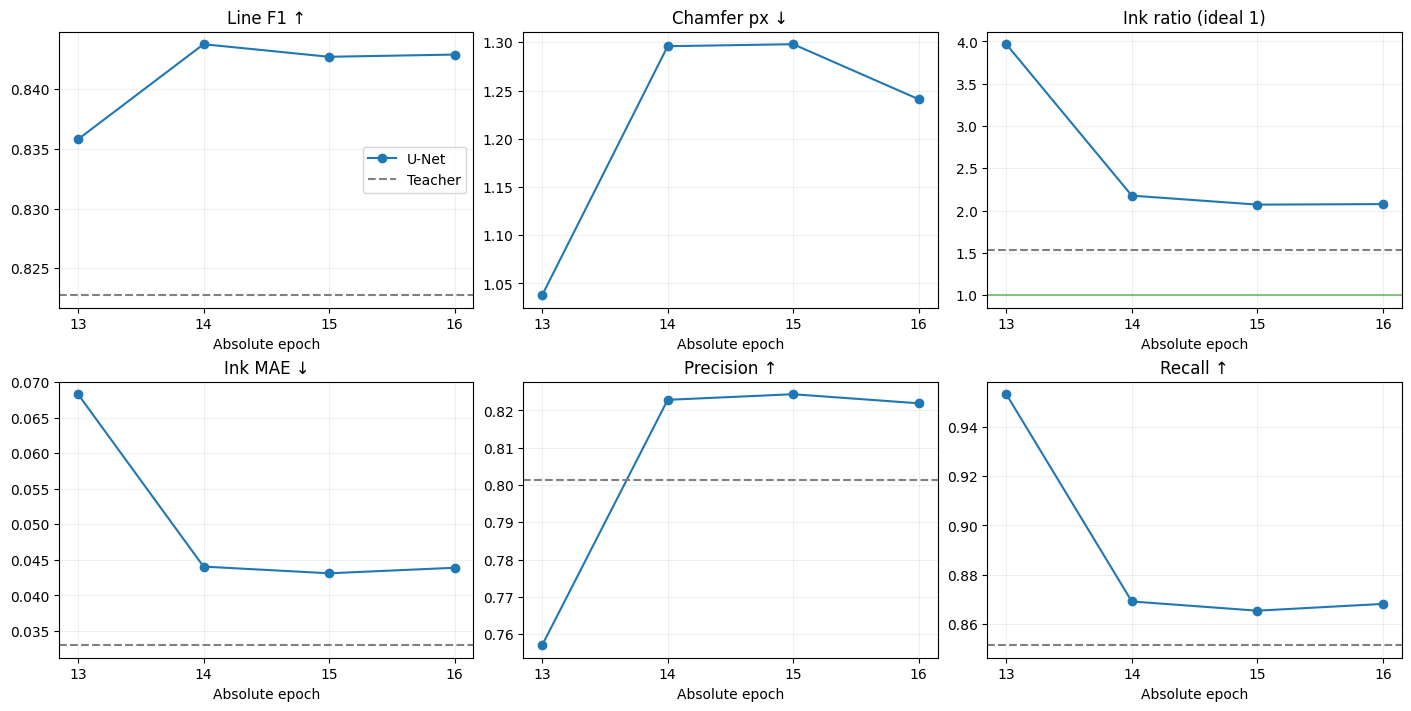

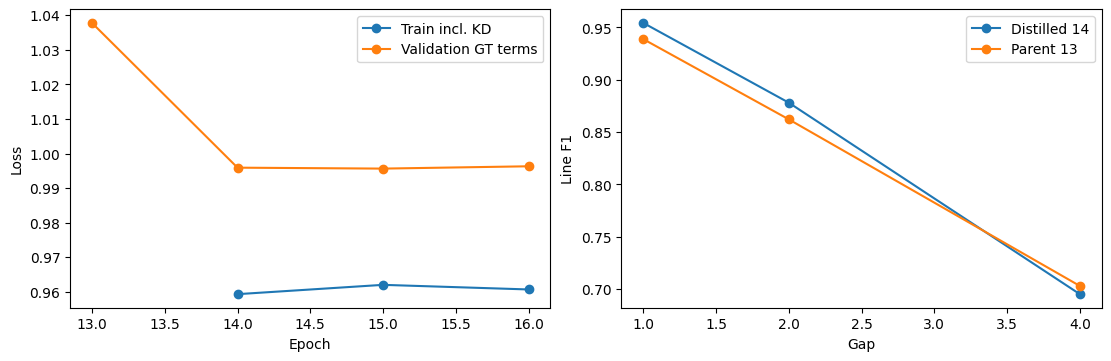

Best distilled epoch: 14 | Checkpoints: /kaggle/working/interframes_kd09/checkpoints


In [ ]:
complete = sorted(
    int(p.name.split("_")[1])
    for p in ckroot.glob("epoch_*")
    if (p / "metrics.json").is_file()
)
assert complete, "Finish validation for at least one distilled epoch."
parent_metrics = read_json(OUT / "validation/epoch_013/summary.json")
summary = [dict(model="Parent", **parent_metrics)]
gt_val = quality[quality.split == "val"]
summary.append(
    dict(model="AnimeInbet", epoch=None, triplets=len(gt_val), **summarize(gt_val))
)
bygap = []
byseq = []
history = []


def group_tables(name, e, df):
    for g, part in df.groupby("gap"):
        bygap.append(
            dict(model=name, epoch=e, gap=g, triplets=len(part), **summarize(part))
        )
    for seq, part in df.groupby("sequence"):
        byseq.append(
            dict(
                model=name, epoch=e, sequence=seq, triplets=len(part), **summarize(part)
            )
        )


group_tables("AnimeInbet", None, gt_val)
for e in [13, *complete]:
    stats = read_json(OUT / "validation" / f"epoch_{e:03d}" / "summary.json")
    df = pd.read_csv(
        OUT / "validation" / f"epoch_{e:03d}" / "per_pair.csv", dtype={"id": str}
    )
    group_tables("Parent" if e == 13 else "Distilled", e, df)
    if e != 13:
        summary.append(dict(model="Distilled", **stats))
        m = read_json(epoch_path(e) / "metrics.json")
        history.append(
            dict(
                epoch=e,
                kd_scale=m["kd_scale"],
                **m["train_terms"],
                val_gt_loss=m["val_gt_loss"],
            )
        )
table = pd.DataFrame(summary)
gaps_df = pd.DataFrame(bygap)
hist = pd.DataFrame(history)
for name, frame in (
    ("validation_comparison", table),
    ("by_gap", gaps_df),
    ("by_sequence", pd.DataFrame(byseq)),
    ("training_history", hist),
):
    csv_atomic(frame, OUT / (name + ".csv"))
columns = [
    "model",
    "epoch",
    "triplets",
    "val_gt_loss",
    "line_f1",
    "precision",
    "recall",
    "chamfer_px",
    "ink_ratio",
    "mae",
]
display(table[columns].round(5))
best = int(
    table[table.model == "Distilled"]
    .sort_values(["line_f1", "chamfer_px", "epoch"], ascending=[False, True, True])
    .iloc[0]
    .epoch
)
for dest, e in (("best.keras", best), ("last.keras", complete[-1])):
    with (epoch_path(e) / "student.keras").open("rb") as f:
        copy_member(f, OUT / dest)
atomic_json(
    OUT / "selected.json",
    dict(
        best_epoch=best,
        last_epoch=complete[-1],
        cutoff=0.5,
        tolerance=2,
        parent_digest=BASE_DIGEST,
        gma=flow_sig,
        teacher_at_inference=False,
    ),
)

fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
curve = table[table.epoch.notna()].sort_values("epoch")
for ax, k, title in zip(
    axes.flat,
    ["line_f1", "chamfer_px", "ink_ratio", "mae", "precision", "recall"],
    [
        "Line F1 ↑",
        "Chamfer px ↓",
        "Ink ratio (ideal 1)",
        "Ink MAE ↓",
        "Precision ↑",
        "Recall ↑",
    ],
):
    ax.plot(curve.epoch, curve[k], "o-", label="U-Net")
    ax.axhline(
        table.loc[table.model == "AnimeInbet", k].iloc[0],
        linestyle="--",
        color="gray",
        label="Teacher",
    )
    if k == "ink_ratio":
        ax.axhline(1, color="green", alpha=0.45)
    ax.set(title=title, xlabel="Absolute epoch", xticks=curve.epoch)
    ax.grid(alpha=0.2)
axes.flat[0].legend()
fig.savefig(OUT / "validation_metrics.png", dpi=140)
plt.show()
plt.close(fig)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
axes[0].plot(hist.epoch, hist.total, "o-", label="Train incl. KD")
axes[0].plot(curve.epoch, curve.val_gt_loss, "o-", label="Validation GT terms")
axes[0].legend()
axes[0].set(xlabel="Epoch", ylabel="Loss")
for (label, e), g in gaps_df[gaps_df.epoch.isin([13, best])].groupby(
    ["model", "epoch"]
):
    axes[1].plot(g.gap, g.line_f1, "o-", label=f"{label} {int(e)}")
axes[1].set(xlabel="Gap", ylabel="Line F1")
axes[1].legend()
fig.savefig(OUT / "loss_and_gap.png", dpi=140)
plt.show()
plt.close(fig)
print("Best distilled epoch:", best, "| Checkpoints:", ckroot)

## Preview generated animations

Choose `checkpoint="best"`, `"last"`, or an epoch number. Use cached GMA motion for the first midpoint; estimate new motion for additional intermediate drawings. Apply `inkcutoff` only to displayed predictions. The example calls compare saved epochs, gaps, and cutoff settings.

In [ ]:
from PIL import ImageDraw
from IPython.display import Image as NotebookImage


@lru_cache(maxsize=3)
def preview_net(epoch):
    return keras.models.load_model(epoch_path(epoch) / "student.keras", compile=False)


def middle(net, a, b, flow):
    x = raster.features_from_low(a, b, flow)
    p = tf.sigmoid(tf.cast(net(x[None], training=False), tf.float32))[0, ..., 0].numpy()
    if not np.isfinite(p).all():
        raise ValueError("Non-finite midpoint")
    return p


def recursive_flow(a, b):
    # GMA reads 8-bit PNGs; keep continuous ink for the U-Net itself.
    imgs = [np.asarray(raster.ink_image(x)) for x in (a, b)]
    key = hashlib.sha256(imgs[0].tobytes() + imgs[1].tobytes()).hexdigest()
    work = TEMP / "preview_pairs"
    work.mkdir(parents=True, exist_ok=True)
    dest = work / "infer" / (key + ".npy")
    if not dest.is_file():
        names = [key + "_a.png", key + "_b.png"]
        for name, img in zip(names, imgs):
            Image.fromarray(img).save(work / name)
        run_gma([dict(id=key, split="infer", a=names[0], b=names[1])], work, work)
    return np.load(dest, allow_pickle=False)


frame_map = {
    (r["sequence"], r["number"]): r["path"]
    for r in read_json(DATA / "frames.json")
    if r["split"] == "val"
}


def animate(seed=42, gap=4, inbetweens=3, fps=4, inkcutoff=0.70, checkpoint="best"):
    if inbetweens not in (1, 3, 7) or not np.isfinite(fps) or fps <= 0:
        raise ValueError("Use 1, 3, or 7 in-betweens and positive fps.")
    if inkcutoff is not None and not 0 <= inkcutoff <= 1:
        raise ValueError("Use a cutoff in [0,1] or None for raw ink.")
    selected = read_json(OUT / "selected.json")
    ep = (
        selected[checkpoint + "_epoch"]
        if checkpoint in ("best", "last")
        else int(checkpoint)
    )
    net = preview_net(ep)
    eligible = sorted(
        (r for r in val_rows if gap is None or r["gap"] == gap), key=lambda r: r["id"]
    )
    if not eligible:
        raise ValueError(f"No validation pairs with gap {gap}")
    r = random.Random(seed).choice(eligible)
    a, b = load_ink(r["a"]), load_ink(r["b"])
    mids = [a, middle(net, a, b, np.load(flow_path(r))), b]
    while len(mids) < inbetweens + 2:
        new = [mids[0]]
        for left, right in zip(mids, mids[1:]):
            new.extend([middle(net, left, right, recursive_flow(left, right)), right])
        mids = new
    gif = []
    nsteps = len(mids) - 1
    for j, p in enumerate(mids):
        canvas = Image.new("RGB", (2 * SIZE + 4, SIZE + 24), "white")
        draw = ImageDraw.Draw(canvas)
        shown = (
            (p >= inkcutoff).astype(np.float32)
            if inkcutoff is not None and 0 < j < nsteps
            else p
        )
        canvas.paste(raster.ink_image(shown), (0, 24))
        draw.text((4, 4), f"Epoch {ep} | {j}/{nsteps}", fill="black")
        start = r["middle_number"] - r["gap"]
        offset, rem = divmod(2 * r["gap"] * j, nsteps)
        ref = frame_map.get((r["sequence"], start + offset)) if rem == 0 else None
        if ref:
            canvas.paste(raster.ink_image(load_ink(ref)), (SIZE + 4, 24))
        draw.text(
            (SIZE + 8, 4),
            "Ground truth" if ref else "No reference at this time",
            fill="black",
        )
        gif.append(canvas)
    path = (
        OUT
        / "previews"
        / f"epoch{ep}_{r['id']}_{inbetweens}mid_{fps}fps_cut{inkcutoff}.gif"
    )
    path.parent.mkdir(exist_ok=True)
    gif[0].save(
        path,
        save_all=True,
        append_images=gif[1:],
        duration=max(10, round(1000 / fps)),
        loop=0,
    )
    print(r["sequence"], "| gap", r["gap"], "|", path)
    display(NotebookImage(data=path.read_bytes(), format="gif"))
    return path


import random
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import Image as NotebookImage, display


def preview_five(
    seed=233, gap=4, inbetweens=1, fps=4, inkcutoff=0.70, checkpoint=16, count=5
):
    if inbetweens not in (1, 3, 7):
        raise ValueError("Choose 1, 3, or 7 in-betweens.")
    if not np.isfinite(fps) or fps <= 0:
        raise ValueError("fps must be positive.")
    if inkcutoff is not None and not 0 <= inkcutoff <= 1:
        raise ValueError("Use an inkcutoff in [0, 1], or None for raw student ink.")

    if checkpoint in ("best", "last"):
        ep = int(read_json(OUT / "selected.json")[f"{checkpoint}_epoch"])
    else:
        ep = int(checkpoint)

    net = preview_net(ep)
    pool = sorted(
        (r for r in val_rows if gap is None or r["gap"] == gap),
        key=lambda r: r["id"],
    )
    if not 1 <= count <= len(pool):
        raise ValueError(
            f"Found {len(pool)} validation pairs for gap={gap}. Check count."
        )

    cases = random.Random(seed).sample(pool, count)
    # A cached teacher drawing is identified by its exact pair of real endpoints.
    teacher_rows = {(r["sequence"], r["middle_number"], r["gap"]): r for r in val_rows}
    folder = OUT / "previews" / "teacher_comparison"
    folder.mkdir(parents=True, exist_ok=True)
    paths = []

    for i, r in enumerate(cases, 1):
        seq = r["sequence"]
        g = int(r["gap"])
        mid = int(r["middle_number"])
        start, end = mid - g, mid + g
        a, b = load_ink(r["a"]), load_ink(r["b"])

        # Student recursion uses its own raw generated drawings as endpoints.
        first = middle(net, a, b, np.load(flow_path(r), allow_pickle=False))
        student = [a, first, b]

        # Time positions are integer ticks, including for fractional source frames.
        steps = inbetweens + 1
        teacher = {0: a, steps: b}
        intervals = [(0, steps)]
        while intervals:
            lo, hi = intervals.pop()
            if hi - lo < 2:
                continue
            j = (lo + hi) // 2
            offset, frac = divmod((end - start) * j, steps)
            halfgap, rem = divmod(g * (hi - lo), steps)
            if frac == 0 and rem == 0:
                row = teacher_rows.get((seq, start + offset, halfgap))
                if row is not None:
                    png = teacher_png_path(row)
                    if png.is_file():
                        teacher[j] = raster.read_ink(png)
            intervals.extend([(lo, j), (j, hi)])

        while len(student) < steps + 1:
            expanded = [student[0]]
            for left, right in zip(student, student[1:]):
                pred = middle(net, left, right, recursive_flow(left, right))
                expanded.extend([pred, right])
            student = expanded

        frames = []
        for j, pred in enumerate(student):
            shown = pred
            if inkcutoff is not None and 0 < j < steps:
                shown = (pred >= inkcutoff).astype(np.float32)

            offset, frac = divmod((end - start) * j, steps)
            ref = frame_map.get((seq, start + offset)) if frac == 0 else None
            truth = load_ink(ref) if ref is not None else None

            panels = [
                (f"Student | epoch {ep}", shown, ""),
                ("AnimeInbet | cached", teacher.get(j), "No cached teacher pair"),
                ("Ground truth", truth, "No reference at this time"),
            ]
            canvas = Image.new("RGB", (3 * SIZE + 8, SIZE + 26), "white")
            draw = ImageDraw.Draw(canvas)
            for col, (title, ink, missing) in enumerate(panels):
                x = col * (SIZE + 4)
                draw.text((x + 4, 5), title, fill="black")
                if ink is None:
                    draw.text((x + 8, 26 + SIZE // 2), missing, fill="gray")
                else:
                    canvas.paste(raster.ink_image(ink), (x, 26))
            frames.append(canvas)

        path = folder / f"ep{ep}_{r['id']}_{inbetweens}mid_{fps}fps_cut{inkcutoff}.gif"
        frames[0].save(
            path,
            save_all=True,
            append_images=frames[1:],
            duration=max(10, round(1000 / fps)),
            loop=0,
        )
        print(f"{i}/{count}  |  {seq}  |  gap {g}  |  {r['id']}")
        display(NotebookImage(data=path.read_bytes(), format="gif"))
        paths.append(path)

    return paths


1/5  |  fist_fight_a_police  |  gap 4  |  4cbee602fe26a3c34be9


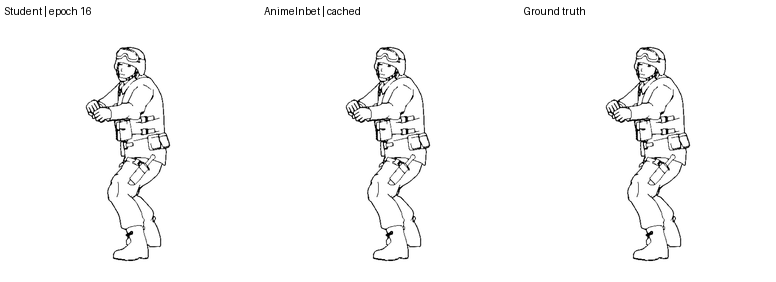

2/5  |  hip_hop_dancing_kachujin_g_rosales  |  gap 4  |  e44dc630ea368baeda12


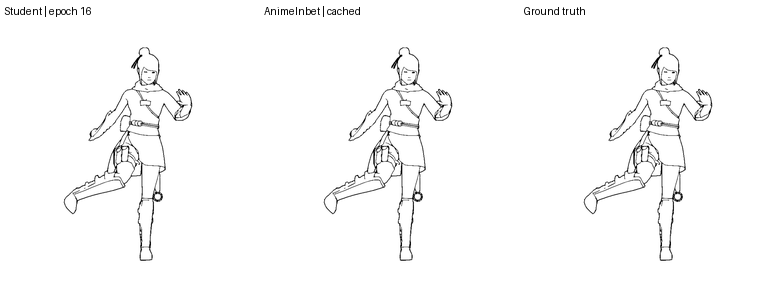

3/5  |  standing_2h_magic_attack_05_warrok  |  gap 4  |  64f4f4f9699ac96f28dc


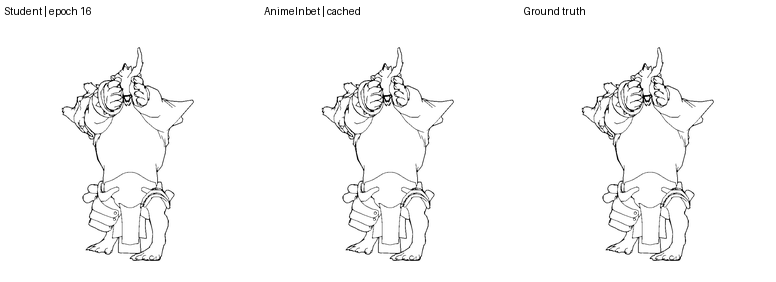

4/5  |  hip_hop_dancing_michelle  |  gap 4  |  d24bd93227a17c757fcb


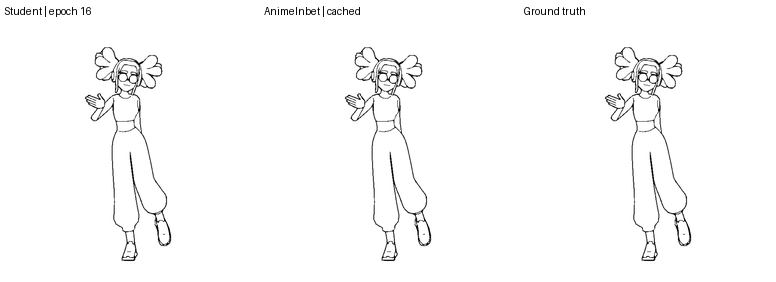

5/5  |  great_sword_slash_ganfaul  |  gap 4  |  ef74a99463fed262f5d5


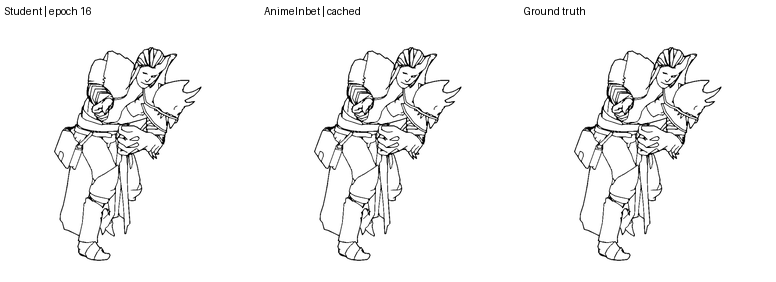

In [ ]:
previews = preview_five(
    seed=233,
    gap=4,
    inbetweens=1,
    fps=4,
    inkcutoff=0.65,
    checkpoint=16,
    count=5,
)

1/5  |  fist_fight_a_police  |  gap 4  |  4cbee602fe26a3c34be9


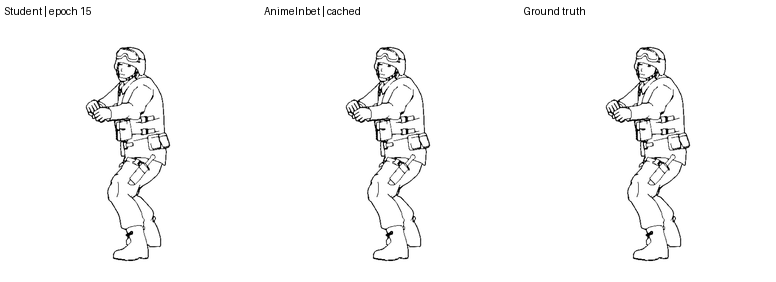

2/5  |  hip_hop_dancing_kachujin_g_rosales  |  gap 4  |  e44dc630ea368baeda12


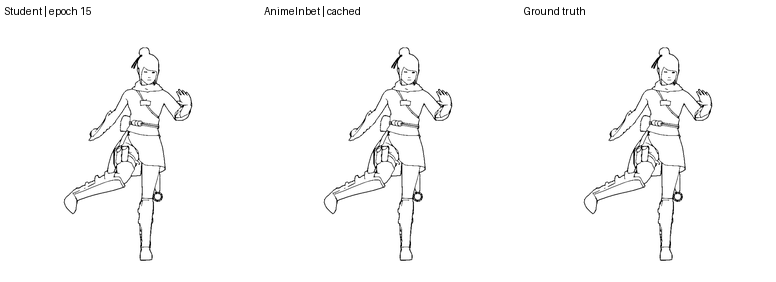

3/5  |  standing_2h_magic_attack_05_warrok  |  gap 4  |  64f4f4f9699ac96f28dc


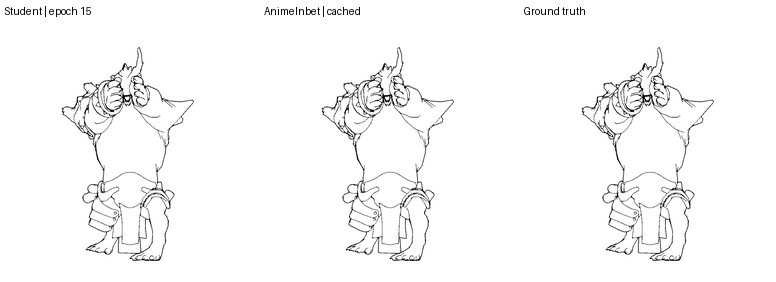

4/5  |  hip_hop_dancing_michelle  |  gap 4  |  d24bd93227a17c757fcb


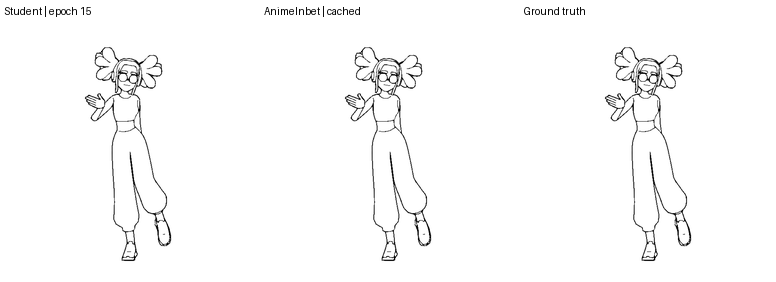

5/5  |  great_sword_slash_ganfaul  |  gap 4  |  ef74a99463fed262f5d5


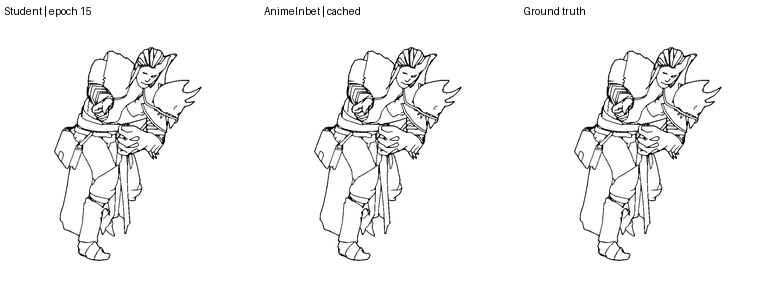

In [ ]:
previews = preview_five(
    seed=233,
    gap=4,
    inbetweens=1,
    fps=4,
    inkcutoff=0.7,
    checkpoint=15,
    count=5,
)

1/5  |  fist_fight_a_police  |  gap 4  |  4cbee602fe26a3c34be9


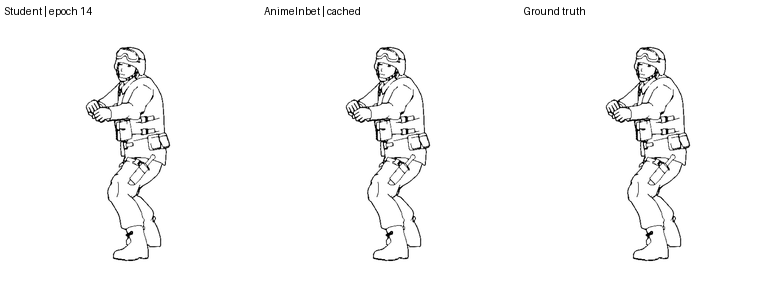

2/5  |  hip_hop_dancing_kachujin_g_rosales  |  gap 4  |  e44dc630ea368baeda12


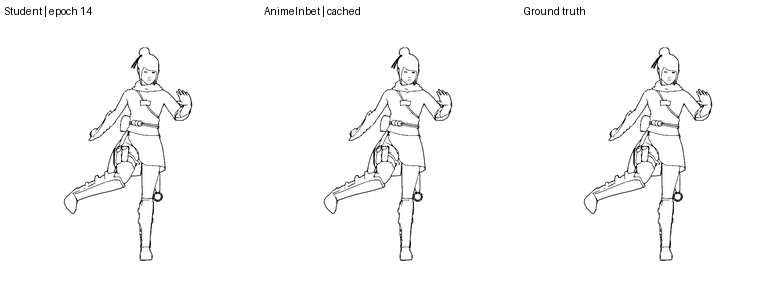

3/5  |  standing_2h_magic_attack_05_warrok  |  gap 4  |  64f4f4f9699ac96f28dc


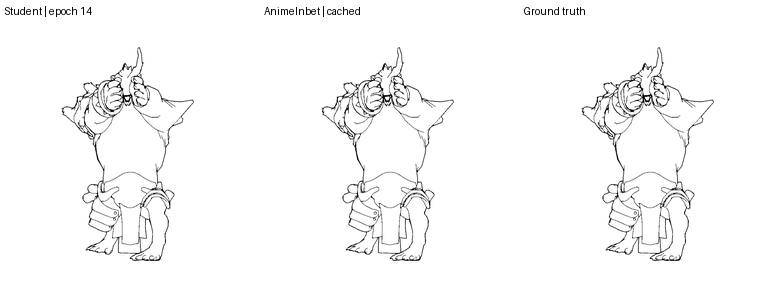

4/5  |  hip_hop_dancing_michelle  |  gap 4  |  d24bd93227a17c757fcb


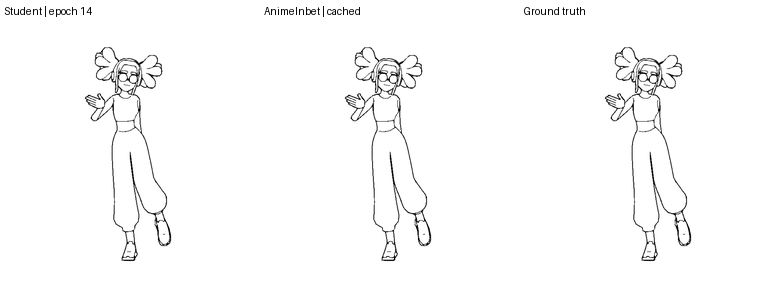

5/5  |  great_sword_slash_ganfaul  |  gap 4  |  ef74a99463fed262f5d5


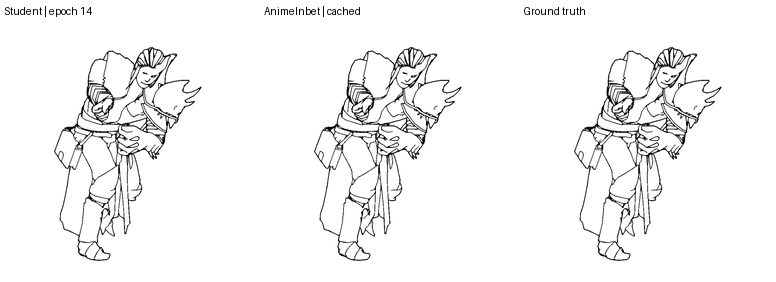

In [ ]:
previews = preview_five(
    seed=233,
    gap=4,
    inbetweens=1,
    fps=4,
    inkcutoff=0.7,
    checkpoint=14,
    count=5,
)

20000_gma-animerun-v2-ft.pth: reconstructing file:   0%|          |  0.00B / 23.8MB            

20000_gma-animerun-v2-ft.pth: downloading bytes:           |  0.00B            

Cache GMA coarse flows:   0%|          | 0/1 [00:00<?, ?it/s]/kaggle/temp/interframes_kd09/GMA/core/network.py:85: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.args.mixed_precision):
/kaggle/temp/interframes_kd09/GMA/core/network.py:93: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.args.mixed_precision):
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/kaggle/temp/interframes_kd09/GMA/core/network.py:112: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args

hip_hop_dancing_uriel_a_plotexia | gap 4 | /kaggle/working/interframes_kd09/previews/epoch14_3ad651fd885d2b904457_3mid_4fps_cut0.7.gif


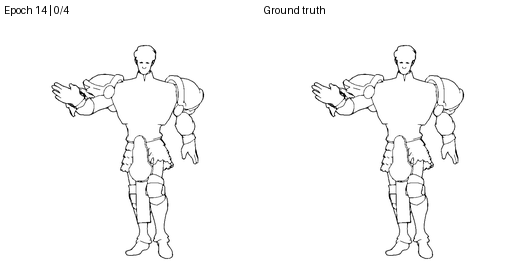

In [18]:
preview = animate(seed=1, gap=4, inbetweens=3, fps=4, inkcutoff=0.7, checkpoint="best")

Cache GMA coarse flows:   0%|          | 0/1 [00:00<?, ?it/s]/kaggle/temp/interframes_kd09/GMA/core/network.py:85: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.args.mixed_precision):
/kaggle/temp/interframes_kd09/GMA/core/network.py:93: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.args.mixed_precision):
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/kaggle/temp/interframes_kd09/GMA/core/network.py:112: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args

1/5  |  breakdance_1990_police  |  gap 1  |  4acc0446c87bf4fbcd49


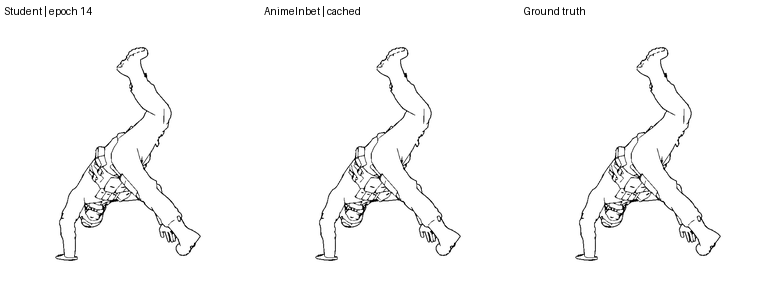

Cache GMA coarse flows:   0%|          | 0/1 [00:00<?, ?it/s]/kaggle/temp/interframes_kd09/GMA/core/network.py:85: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.args.mixed_precision):
/kaggle/temp/interframes_kd09/GMA/core/network.py:93: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.args.mixed_precision):
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/kaggle/temp/interframes_kd09/GMA/core/network.py:112: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args

2/5  |  great_sword_slash_kachujin_g_rosales  |  gap 1  |  e0c20b2af13c611394c3


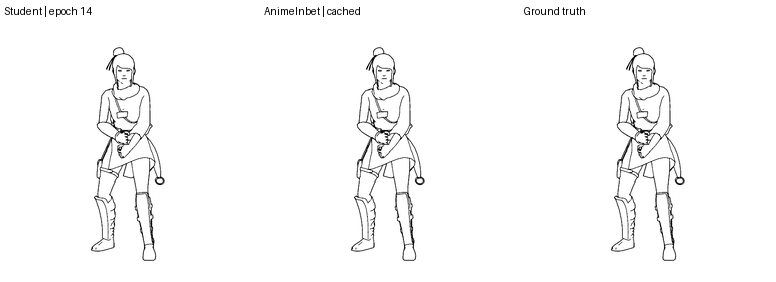

Cache GMA coarse flows:   0%|          | 0/1 [00:00<?, ?it/s]/kaggle/temp/interframes_kd09/GMA/core/network.py:85: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.args.mixed_precision):
/kaggle/temp/interframes_kd09/GMA/core/network.py:93: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.args.mixed_precision):
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/kaggle/temp/interframes_kd09/GMA/core/network.py:112: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args

3/5  |  freehang_climb_warrok  |  gap 1  |  624d941791db219fccc4


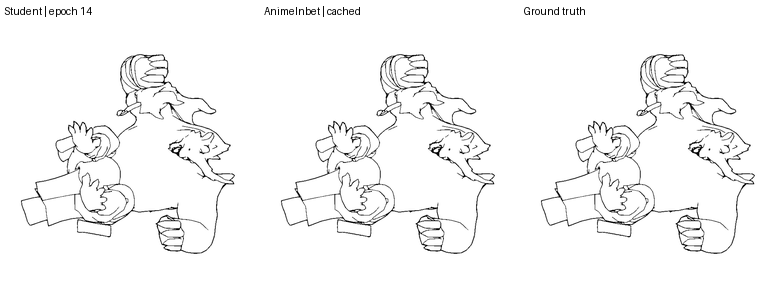

Cache GMA coarse flows:   0%|          | 0/1 [00:00<?, ?it/s]/kaggle/temp/interframes_kd09/GMA/core/network.py:85: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.args.mixed_precision):
/kaggle/temp/interframes_kd09/GMA/core/network.py:93: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.args.mixed_precision):
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/kaggle/temp/interframes_kd09/GMA/core/network.py:112: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args

4/5  |  great_sword_slash_kachujin_g_rosales  |  gap 1  |  cf6d6a65fd4916d19d50


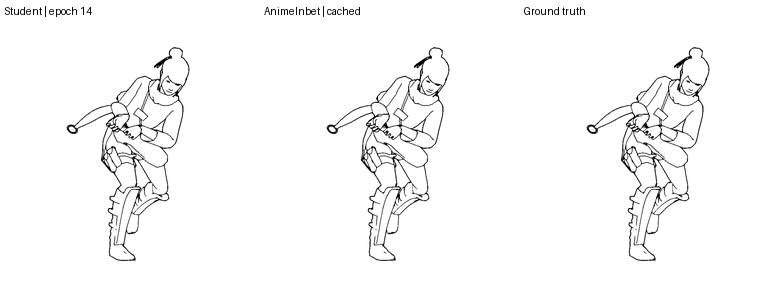

Cache GMA coarse flows:   0%|          | 0/1 [00:00<?, ?it/s]/kaggle/temp/interframes_kd09/GMA/core/network.py:85: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.args.mixed_precision):
/kaggle/temp/interframes_kd09/GMA/core/network.py:93: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=self.args.mixed_precision):
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/kaggle/temp/interframes_kd09/GMA/core/network.py:112: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args

5/5  |  standing_2h_magic_attack_05_warrok  |  gap 1  |  eb8b4db88dd475dbe3ed


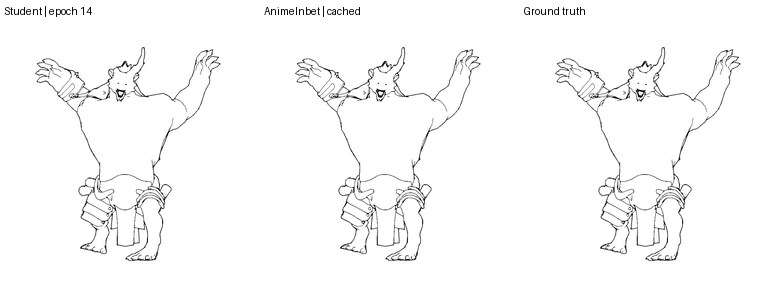

[PosixPath('/kaggle/working/interframes_kd09/previews/teacher_comparison/ep14_4acc0446c87bf4fbcd49_3mid_4fps_cutNone.gif'),
 PosixPath('/kaggle/working/interframes_kd09/previews/teacher_comparison/ep14_e0c20b2af13c611394c3_3mid_4fps_cutNone.gif'),
 PosixPath('/kaggle/working/interframes_kd09/previews/teacher_comparison/ep14_624d941791db219fccc4_3mid_4fps_cutNone.gif'),
 PosixPath('/kaggle/working/interframes_kd09/previews/teacher_comparison/ep14_cf6d6a65fd4916d19d50_3mid_4fps_cutNone.gif'),
 PosixPath('/kaggle/working/interframes_kd09/previews/teacher_comparison/ep14_eb8b4db88dd475dbe3ed_3mid_4fps_cutNone.gif')]

In [ ]:
preview_five(
    seed=233, gap=1, inbetweens=3, fps=4, inkcutoff=None, checkpoint=14, count=5
)

1/5  |  fist_fight_a_warrok  |  gap 2  |  49af7a26e5d033f2746d


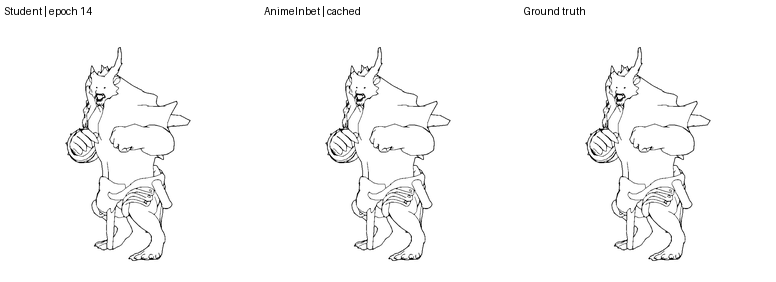

2/5  |  great_sword_slash_peasant_girl  |  gap 2  |  e20a03c6fd50b06a8c96


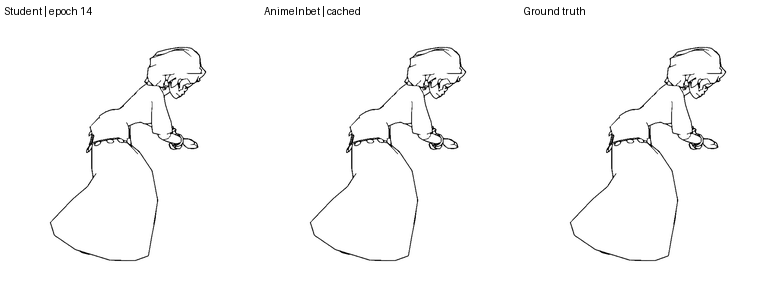

3/5  |  hip_hop_dancing_michelle  |  gap 2  |  61ccd0e2b9a4f2a9f9b1


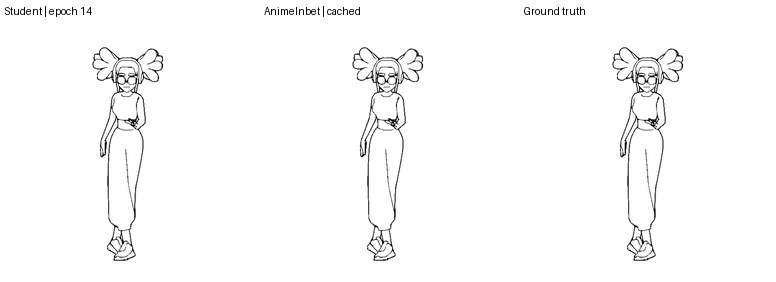

4/5  |  great_sword_slash_uriel_a_plotexia  |  gap 2  |  d061c8235f8e41ffdc42


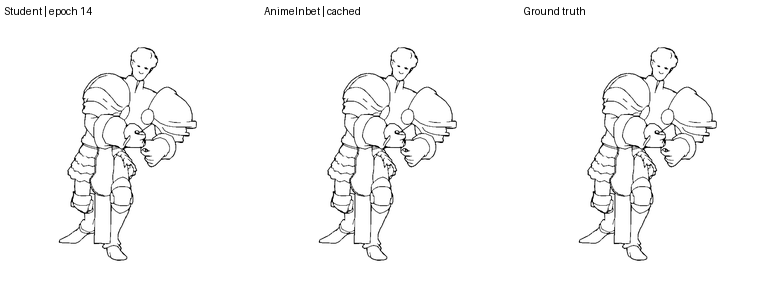

5/5  |  chapa-giratoria_police  |  gap 2  |  ec9b5f55f3640e04c268


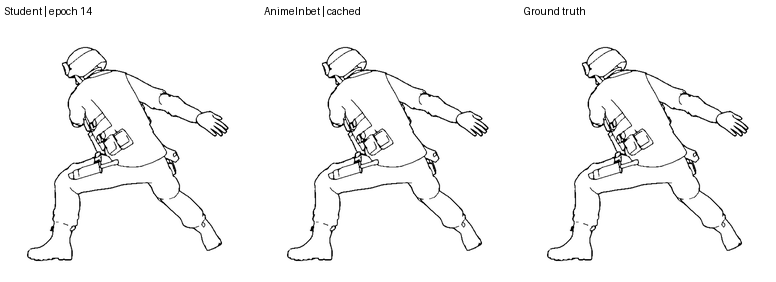

[PosixPath('/kaggle/working/interframes_kd09/previews/teacher_comparison/ep14_49af7a26e5d033f2746d_1mid_4fps_cutNone.gif'),
 PosixPath('/kaggle/working/interframes_kd09/previews/teacher_comparison/ep14_e20a03c6fd50b06a8c96_1mid_4fps_cutNone.gif'),
 PosixPath('/kaggle/working/interframes_kd09/previews/teacher_comparison/ep14_61ccd0e2b9a4f2a9f9b1_1mid_4fps_cutNone.gif'),
 PosixPath('/kaggle/working/interframes_kd09/previews/teacher_comparison/ep14_d061c8235f8e41ffdc42_1mid_4fps_cutNone.gif'),
 PosixPath('/kaggle/working/interframes_kd09/previews/teacher_comparison/ep14_ec9b5f55f3640e04c268_1mid_4fps_cutNone.gif')]

In [ ]:
preview_five(
    seed=233, gap=2, inbetweens=1, fps=4, inkcutoff=None, checkpoint=14, count=5
)

1/5  |  breakdance_1990_police  |  gap 1  |  4acc0446c87bf4fbcd49


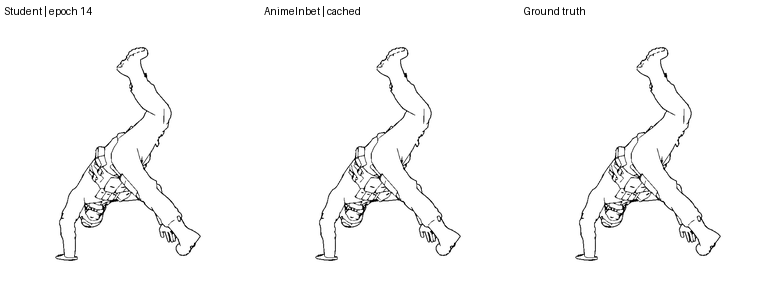

2/5  |  great_sword_slash_kachujin_g_rosales  |  gap 1  |  e0c20b2af13c611394c3


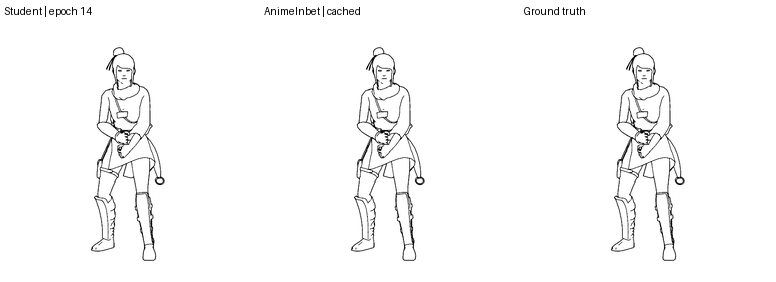

3/5  |  freehang_climb_warrok  |  gap 1  |  624d941791db219fccc4


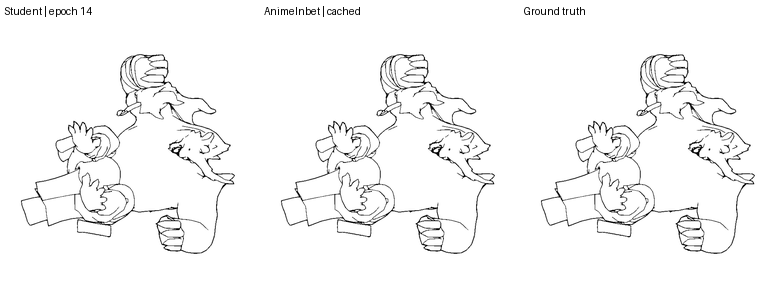

4/5  |  great_sword_slash_kachujin_g_rosales  |  gap 1  |  cf6d6a65fd4916d19d50


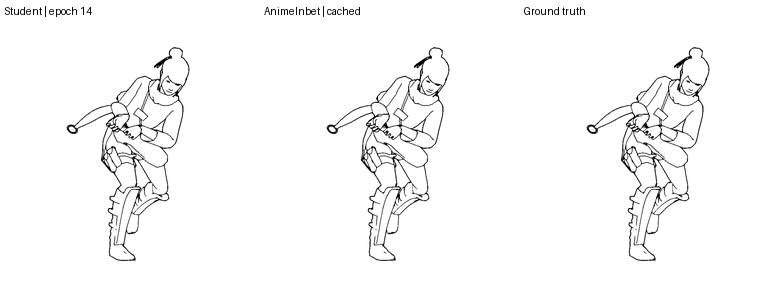

5/5  |  standing_2h_magic_attack_05_warrok  |  gap 1  |  eb8b4db88dd475dbe3ed


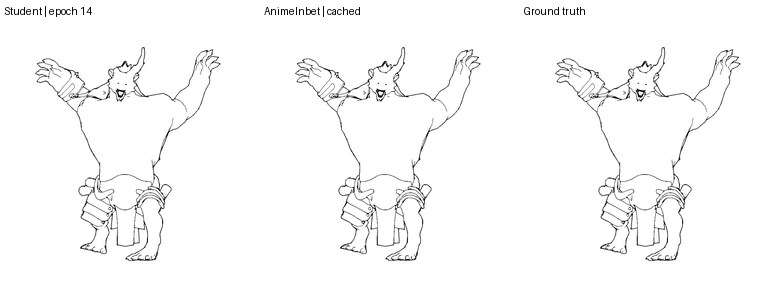

[PosixPath('/kaggle/working/interframes_kd09/previews/teacher_comparison/ep14_4acc0446c87bf4fbcd49_1mid_4fps_cutNone.gif'),
 PosixPath('/kaggle/working/interframes_kd09/previews/teacher_comparison/ep14_e0c20b2af13c611394c3_1mid_4fps_cutNone.gif'),
 PosixPath('/kaggle/working/interframes_kd09/previews/teacher_comparison/ep14_624d941791db219fccc4_1mid_4fps_cutNone.gif'),
 PosixPath('/kaggle/working/interframes_kd09/previews/teacher_comparison/ep14_cf6d6a65fd4916d19d50_1mid_4fps_cutNone.gif'),
 PosixPath('/kaggle/working/interframes_kd09/previews/teacher_comparison/ep14_eb8b4db88dd475dbe3ed_1mid_4fps_cutNone.gif')]

In [ ]:
preview_five(
    seed=233, gap=1, inbetweens=1, fps=4, inkcutoff=None, checkpoint=14, count=5
)

## Download results and reusable caches

Export completed files at any point, including partial preparation or training. Download both ZIPs for a new session, then attach them through `RESULTS_INPUT` and `CACHE_INPUTS`. The export switches let you package either folder separately.

In [ ]:
from IPython.display import FileLink, display
import os, zipfile, shutil
from pathlib import Path
from tqdm.auto import tqdm

DOWNLOAD_RESULTS = True
DOWNLOAD_CACHE = True
working = Path("/kaggle/working")


def download_folder(src, zip_name):
    files = [
        p
        for p in src.rglob("*")
        if p.is_file()
        and not any(
            s.startswith(".") or ".part." in s or s.endswith(".part")
            for s in p.relative_to(src).parts
        )
    ]
    if not files:
        print("No completed files yet in", src)
        return
    needed = sum(p.stat().st_size + 300 for p in files)
    if shutil.disk_usage(working).free < needed:
        print(
            f"ZIP needs about {needed / 2**30:.2f} GiB free. The source folder is available in Kaggle Output:",
            src,
        )
        return
    dest = working / zip_name
    tmp = dest.with_suffix(".part.zip")
    with zipfile.ZipFile(
        tmp, "w", compression=zipfile.ZIP_STORED, allowZip64=True
    ) as z:
        for p in tqdm(files, desc=zip_name):
            z.write(p, (Path(src.name) / p.relative_to(src)).as_posix())
    tmp.replace(dest)
    print(f"{dest.stat().st_size / 2**30:.2f} GiB · click to download")
    os.chdir(working)
    display(FileLink(dest.name))


if DOWNLOAD_RESULTS:
    download_folder(OUT, "09_models_checkpoints_results.zip")
if DOWNLOAD_CACHE:
    download_folder(CACHE, "09_reusable_gma_animeinbet_cache.zip")

09_models_checkpoints_results.zip:   0%|          | 0/895 [00:00<?, ?it/s]

0.14 GiB · click to download


/kaggle/working/09_models_checkpoints_results.zip

09_reusable_gma_animeinbet_cache.zip:   0%|          | 0/175158 [00:00<?, ?it/s]

1.43 GiB · click to download


/kaggle/working/09_reusable_gma_animeinbet_cache.zip